# HSA_Cam_B_023.py
This file uses the LHHW_Model of kinetics and KLD to determine kinetic parameters and an optimal next experiment.

HSA_Cam_B_008 .py is the model. This uses heteroscedastic noise at 5% and exponential priors. Also saves the log-likelihodd values.

Analysis from the related python script.

### Plan:
* load the data
* generate the plots
* check the reduction in KLD
* check the reduction in HDI
* check the parameter uncertainties
* check the exploration pattern

### Results:
* Leave out the first 4 experiments completely

In [ ]:
import json
from pathlib import Path
import sys

sys.argv = [""]
import numpy as np
import matplotlib.pyplot as plt
import torch
import arviz as az
import ICIW_Plots

plt.style.use("ICIWstyle")

In [ ]:
from HSA_Cam_B_023_pyro import (
    predict,
    generate_synthetic_data,
    calculate_partial_pressures,
    kl_divergence_between_models,
)
from HSA_Mo_B_009_pyro import kinetics_model, validate_against_holdout, sample_prior

In [ ]:
def max_func(x, idata, key="posterior"):
    T = x[0].reshape(1, 1)
    p = x[1].reshape(1, 1)
    c2h = x[2].reshape(1, 1)
    f = x[3].reshape(1, 1)
    c2i = x[4].reshape(1, 1)
    p_i = calculate_partial_pressures(p, c2h, f, c2i)
    res = predict(
        idata,
        T,
        p_i,
        num_samples=1000,
        key=key,
    )
    HDI = torch.quantile(res, 0.975) - torch.quantile(res, 0.025)
    return -HDI

In [ ]:
def evaluate_conditions(proposal, idata, key="posterior"):
    """
    Evaluate posterior predictions over temperature range at given conditions.

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions
        idata: ArviZ InferenceData with posterior samples

    Returns:
        predictions: Array of shape (100, n_samples) with rate predictions
    """
    # Extract conditions from proposal
    p = torch.tensor([[proposal[1]]])
    c2h = torch.tensor([[proposal[2]]])
    f = torch.tensor([[proposal[3]]])
    c2i = torch.tensor([[proposal[4]]])

    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, f, c2i)

    # Temperature range for evaluation
    T = torch.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # Generate posterior predictions
    predictions = predict(idata, T, p_i, key=key, num_samples=1000)

    return predictions


def evaluate_true_model(proposal):
    """
    Compute true model predictions (for comparison with posterior).

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions

    Returns:
        true_rates: Array of shape (100, 1) with true rate predictions
    """
    # Extract conditions
    p = torch.tensor([[proposal[1]]])
    c2h = torch.tensor([[proposal[2]]])
    f = torch.tensor([[proposal[3]]])
    c2i = torch.tensor([[proposal[4]]])

    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, f, c2i)

    # Temperature range
    T = torch.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # True model prediction
    _, _, true_rates = generate_synthetic_data(T, p, c2h, f, c2i, rel_noise_std=0.0)

    return true_rates.cpu().numpy()


def plot_predictions(fig, ax, proposal, posterior_preds, true_preds, T_range):
    """
    Visualize posterior predictions vs true model with uncertainty.

    Args:
        proposal: Experimental conditions [T, p, c2h, f, c2i]
        posterior_preds: Posterior predictions (100, n_samples)
        true_preds: True model predictions (100, 1)
        T_range: Temperature values for x-axis
    """

    # Posterior mean
    ax.plot(
        T_range,
        posterior_preds.mean(axis=1),
        label="Posterior Mean",
        # color="blue",
    )

    # True model
    ax.plot(
        T_range,
        true_preds.squeeze(),
        label="True Model",
        color="black",
        linestyle="--",
        linewidth=2,
    )

    # 95% credible interval
    ax.fill_between(
        T_range,
        np.percentile(posterior_preds, 2.5, axis=1),
        np.percentile(posterior_preds, 97.5, axis=1),
        alpha=0.3,
        # color="blue",
        label="95% HDI",
    )

    ax.legend(loc="upper left")

    # Add condition text
    # condition_text = (
    #     f"Conditions:\n"
    #     f"p = {proposal[1]:.1f} bar\n"
    #     f"CO2/H2 = {proposal[2]:.2f}\n"
    #     f"Feed ratio = {proposal[3]:.1f}\n"
    #     f"CO2/Inert = {proposal[4]:.2f}"
    # )
    # ax.text(
    #     0.02,
    #     0.8,
    #     condition_text,
    #     transform=ax.transAxes,
    #     fontsize=9,
    #     verticalalignment="top",
    #     bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5),
    # )

    # Second y-axis for HDI width
    # ax2 = ax.twinx()
    # hdi_width = np.percentile(posterior_preds, 97.5, axis=1) - np.percentile(
    #     posterior_preds, 2.5, axis=1
    # )
    # ax2.plot(T_range, hdi_width, color="orange", alpha=0.7, linewidth=2)
    # ax2.set_ylabel("HDI Width", color="orange")
    # ax2.tick_params(axis="y", labelcolor="orange")

    # plt.title("Posterior Predictions vs True Model")
    # plt.tight_layout()
    return fig, ax

In [ ]:
# exp_run_name = "soggy-nebula"  # MCMC
exp_run_name = "limitless-grenade"  # VI
data_path = Path(f"data/{exp_run_name}/")
sum_file = data_path / f"experiment_summary_{exp_run_name}.json"
trace_files = sorted(data_path.glob("trace_*.nc"))

In [ ]:
idatas = []
for trace_file in trace_files:
    idata = az.from_netcdf(trace_file)
    idatas.append(idata)

In [ ]:
for i, idata in enumerate(idatas):
    if i > 0:
        idata.prior = idatas[i - 1].posterior

In [ ]:
with open(sum_file, "r") as f:
    exp_summary = json.load(f)

In [ ]:
proposals = np.array(exp_summary["trials"][-1]["observed"]["x"])
r_obs = np.array(exp_summary["trials"][-1]["observed"]["y"])

### Display the results:

In [ ]:
from ipywidgets import interact, IntSlider


@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
    j=IntSlider(
        min=0, max=len(proposals) - 1, step=1, value=0, description="Proposal:"
    ),
)
def plot_interactive(i, j):
    fig = ICIW_Plots.figure(layout="double_column")
    ax = ICIW_Plots.make_rect_ax(
        fig,
        ax_width=7.5 * ICIW_Plots.cm2inch,
        ax_height=5.0 * ICIW_Plots.cm2inch,
        xlabel="$T$ / K",
        ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
    )
    test_res = evaluate_conditions(
        proposal=proposals[j],
        idata=idatas[i],
        key="posterior" if i > 0 else "prior",
    )
    true_res = evaluate_true_model(
        proposal=proposals[j],
    )
    plot_predictions(
        fig,
        ax,
        proposal=proposals[j],
        posterior_preds=test_res,
        true_preds=true_res,
        T_range=np.linspace(500, 600, 100),
    )
    fig = plt.gcf()
    axs = fig.axes
    axs[0].set(
        ylim=(0, 0.0006),
        xlabel="$T$ / K",
        xlim=(500, 600),
    )
    axs[0].scatter(
        proposals[j, 0], r_obs[j], color="red", label="Observed Data Point", zorder=5
    )
    plt.show()

interactive(children=(IntSlider(value=0, description='Iteration:', max=15), IntSlider(value=0, description='Pr…

### Generate the exploration pattern

C:\Users\hanne\AppData\Local\Temp\ipykernel_28440\2035428282.py:81: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



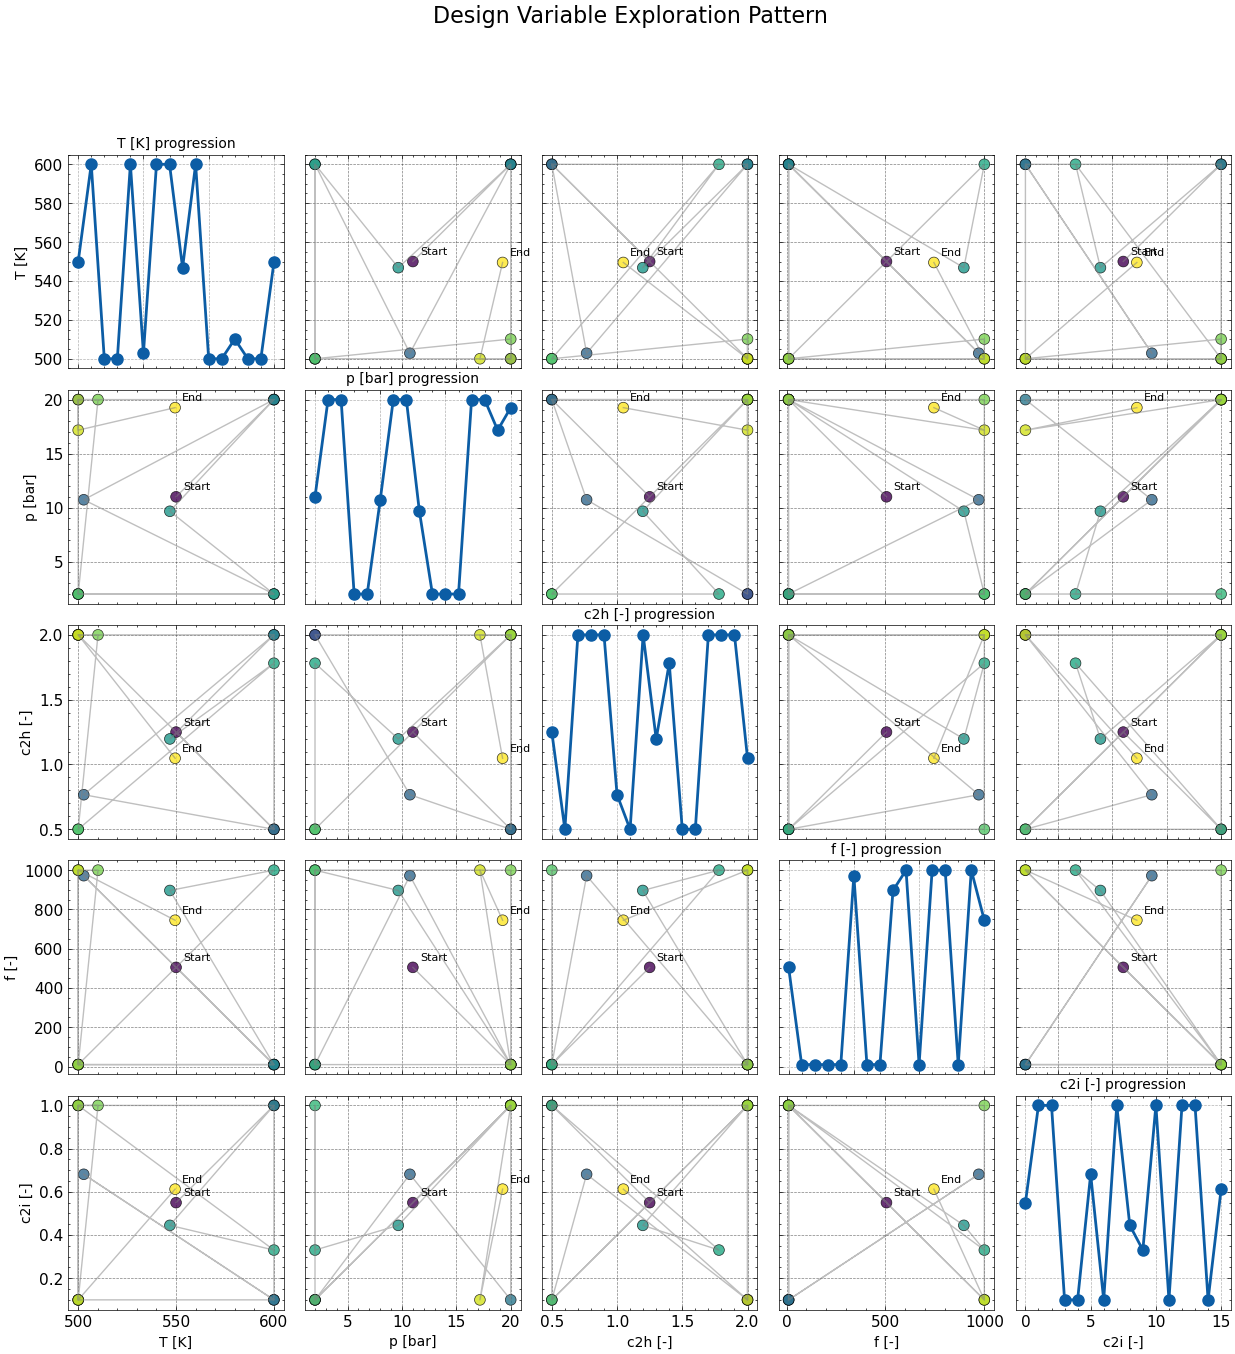

In [ ]:
# create a 5x5 matrix plot with no gaps between the subplots
fig, axs = plt.subplots(
    5,
    5,
    figsize=(15, 15),
    sharex=False,
    sharey=False,
    gridspec_kw={"hspace": 0.1, "wspace": 0.1},
)

# Variable names for labeling
var_names = ["T [K]", "p [bar]", "c2h [-]", "f [-]", "c2i [-]"]

# Assuming proposals array exists with shape (n_experiments, 5)
n_experiments = proposals.shape[0]
experiment_order = np.arange(n_experiments)

for i in range(5):
    for j in range(5):
        ax = axs[i, j]

        if i == j:  # Diagonal: time series of each variable
            ax.plot(experiment_order, proposals[:, i], "o-", linewidth=2, markersize=8)
            ax.set_title(f"{var_names[i]} progression", fontsize=10, pad=5)
            ax.grid(True, alpha=0.3)
            if i == 4:  # Bottom row
                ax.set_xlabel("Experiment #")
        else:  # Off-diagonal: scatter plots
            # Color points by experiment order for temporal information
            scatter = ax.scatter(
                proposals[:, j],
                proposals[:, i],
                c=experiment_order,
                cmap="viridis",
                s=60,
                alpha=0.8,
                edgecolors="black",
                linewidth=0.5,
            )

            # Add trajectory lines
            ax.plot(
                proposals[:, j],
                proposals[:, i],
                "-",
                alpha=0.5,
                color="gray",
                linewidth=1,
            )

            # Label first and last points
            ax.annotate(
                "Start",
                (proposals[0, j], proposals[0, i]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=8,
            )
            if n_experiments > 1:
                ax.annotate(
                    "End",
                    (proposals[-1, j], proposals[-1, i]),
                    xytext=(5, 5),
                    textcoords="offset points",
                    fontsize=8,
                )

        # Set labels only on edges
        if i == 4:  # Bottom row
            ax.set_xlabel(var_names[j], fontsize=10)
        if j == 0:  # Left column
            ax.set_ylabel(var_names[i], fontsize=10)

        # Remove tick labels for inner plots
        if i < 4:
            ax.set_xticklabels([])
        if j > 0:
            ax.set_yticklabels([])

plt.suptitle("Design Variable Exploration Pattern", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

## Quantify the information gain

In [ ]:
import xarray

info_gains = []
rel_waics = []
ELPDdatas = []
for i in range(0, len(idatas)):
    klds = kl_divergence_between_models(
        idata_new=idatas[i],
        idata_old=idatas[i],
        key_new="posterior",
        key_old="prior",
        var_names=[
            "k0",
            "Ea_k",
            "A_oh",
            "dH_oh",
            "A_h2",
            "dH_h2",
            "A_mix",
            "dH_mix",
            "sigma_r",
        ],
    )
    info_gains.append(klds)

    ELPDdata = az.loo(
        idatas[i],
        var_name="r",
        pointwise=True,
        scale="deviance",
    )
    ELPDdatas.append(ELPDdata)
    rel_waics.append(ELPDdata.elpd_loo / idatas[i].observed_data.sizes["obs"])
kldses = []
for i, klds in enumerate(info_gains):
    print(klds)
    print(klds.sum())
    kldses.append(klds.sum())

c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\stats\stats.py:797: UserWarning:

Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.

c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\stats\stats.py:840: UserWarning:

The point-wise LOO is the same with the sum LOO, please double check the Observed RV in your model to make sure it returns element-wise logp.

c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\stats\stats.py:797: UserWarning:

Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well i

[0.29406344 0.29616923 0.11515534 0.06218665 0.40699339 2.6467072
 0.33329151 1.79164641 0.76283627]
6.709049433992221
[ 0.06078034  1.97461941  0.05487975  0.02337555  0.2211598  11.87138039
  0.08256271  7.84157486  0.08445271]
22.21478553779867
[0.02985942 0.1937685  0.02180643 0.03722531 0.1507996  0.11030505
 0.14780235 0.2118912  1.56808764]
2.471545497323724
[ 1.39846263  0.24553367  0.06628474 -0.01496207  0.22124442  0.02337897
  1.48668946  0.058269    0.16921503]
3.654115863755879
[0.71436677 0.56190023 0.01278742 0.00547027 1.56527682 0.04780389
 0.49751793 0.09836113 0.09461999]
3.5981044553210757
[0.10837709 0.44700851 0.07059666 0.03965723 0.1639298  0.01846764
 0.10312012 0.02131336 0.57576547]
1.5482358827842821
[0.19224418 0.24498694 0.06436126 0.04801786 0.45748358 0.01938029
 0.21245144 0.15174414 0.88432999]
2.274999678768409
[0.02714386 0.05672519 0.06034767 0.02159311 0.098912   0.00687659
 0.08947178 0.05625695 0.06369333]
0.4810204768028794
[0.01740889 0.061099

c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\stats\stats.py:797: UserWarning:

Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.



In [ ]:
idatas[4].observed_data

<xarray.Dataset> Size: 60B
Dimensions:  (obs: 5)
Coordinates:
  * obs      (obs) int64 40B 0 1 2 3 4
Data variables:
    r        (obs) float32 20B ...
Attributes:
    created_at:     2025-11-11T10:55:03.317899+00:00
    arviz_version:  0.22.0

In [ ]:
expected_KLDs = [
    trial["next_proposal"]["expected_KLD"] for trial in exp_summary["trials"]
]

Text(0, 0.5, 'info gain as per KL divergence')

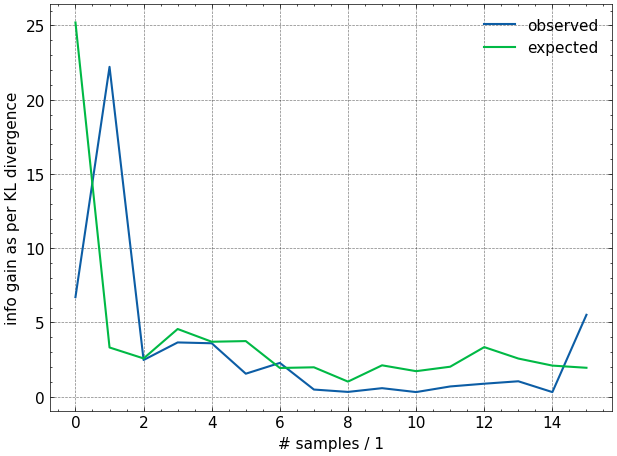

In [ ]:
plt.plot(np.arange(len(kldses)), kldses, label="observed")
plt.plot(np.arange(len(kldses)), expected_KLDs, label="expected")
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")

Text(0, 0.5, 'info gain as per KL divergence')

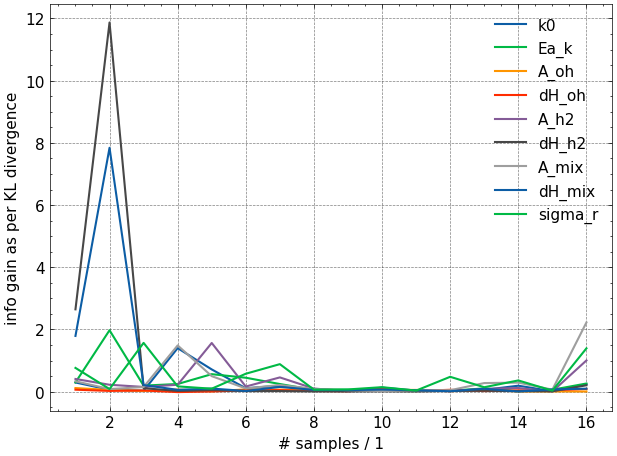

In [ ]:
plt.plot(
    np.arange(len(kldses)) + 1,
    info_gains,
    label=[
        "k0",
        "Ea_k",
        "A_oh",
        "dH_oh",
        "A_h2",
        "dH_h2",
        "A_mix",
        "dH_mix",
        "sigma_r",
    ],
)
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")

Text(0, 0.5, 'info gain as per WAIC')

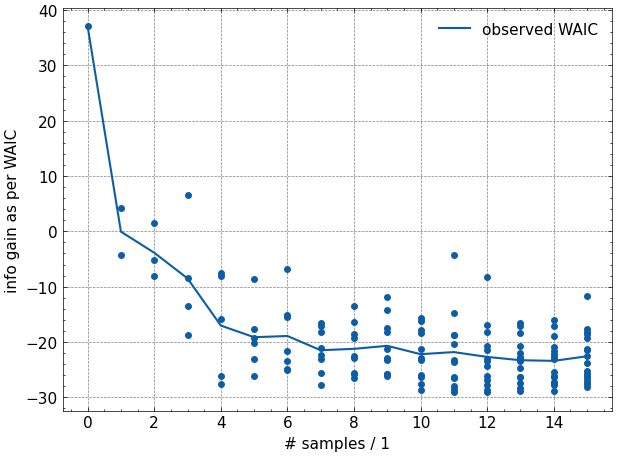

In [ ]:
plt.plot(np.arange(len(kldses)), rel_waics, label="observed WAIC")
ax = plt.gca()
for i, elpd in enumerate(ELPDdatas):
    ax.scatter(np.full_like(elpd.loo_i, i), elpd.loo_i, c=f"C0")
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per WAIC")

In [ ]:
from ipywidgets import Dropdown

print(list(idatas[0].posterior.data_vars))


@interact(
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    )
)
def interactive(key):
    az.plot_density(
        [idata for idata in idatas],
        group="posterior",
        var_names=key,
        shade=0.2,
    )

['k0', 'Ea_k', 'A_oh', 'dH_oh', 'A_h2', 'dH_h2', 'A_mix', 'dH_mix', 'sigma_r']


interactive(children=(Dropdown(description='Parameter:', options=('k0', 'Ea_k', 'A_oh', 'dH_oh', 'A_h2', 'dH_h…

In [ ]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    ),
)
def interactive(i, key):
    az.plot_dist_comparison(idatas[i], var_names=[key], figsize=(4, 4))

interactive(children=(IntSlider(value=0, description='Iteration:', max=15), Dropdown(description='Parameter:',…

In [ ]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
)
def interactive(i):
    axs = az.plot_pair(
        idatas[i],
        group="posterior",
        var_names=["k0", "Ea_k"],
        kind=["scatter", "kde"],
        point_estimate="median",
        marginals=True,
    ).flatten()
    axs[2].set(
        xlim=(8e-5, 1e-3),
        # xscale="log",
        ylim=(30e3, 130e3),
    )

interactive(children=(IntSlider(value=0, description='Iteration:', max=15), Output()), _dom_classes=('widget-i…

In [ ]:
az.summary(idatas[-1], round_to=5)

arviz - WARNING - Shape validation failed: input_shape: (1, 4000), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
k0,0.00034,0.00002,0.00030,0.00037,0.00000,0.00000,3802.52902,3805.20881,NaN
Ea_k,77399.02344,2631.73853,72839.62500,82699.62500,45.30729,30.96826,3357.49997,3926.40335,NaN
A_oh,0.97313,1.28512,0.01274,2.83929,0.02081,0.08291,3429.89188,3707.77800,NaN
dH_oh,9535.39355,12013.57617,237.06993,27424.80078,191.10071,582.73182,3764.76755,3517.29933,NaN
A_h2,0.43982,0.05591,0.34142,0.54766,0.00087,0.00069,4132.45060,3485.61224,NaN
dH_h2,-10131.11230,2125.70410,-14111.43457,-6172.82227,36.33354,24.78063,3415.45325,3998.88700,NaN
A_mix,0.85135,0.06554,0.73253,0.97152,0.00102,0.00075,4165.83955,3917.02314,NaN
dH_mix,-10621.95898,2195.49438,-14550.67383,-6414.58203,38.58606,25.88174,3268.99876,3891.84392,NaN
sigma_r,0.06967,0.01380,0.04623,0.09635,0.00023,0.00016,3694.04027,3851.82187,NaN


<Axes: xlabel='r'>

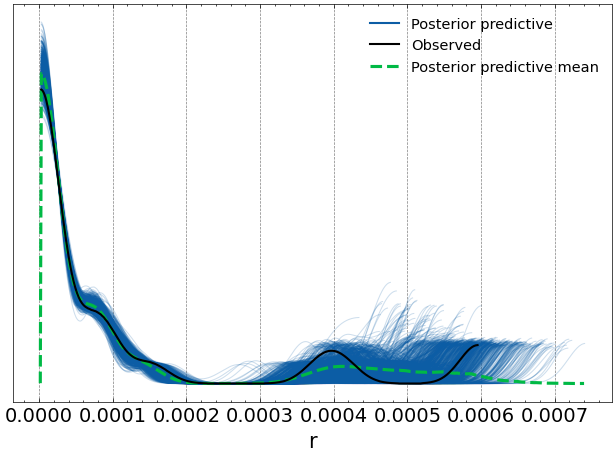

In [ ]:
az.plot_ppc(
    idatas[-1],
    num_pp_samples=1000,
    # kind="scatter",
    # var_names=["r_pred"],
)

<Axes: title={'center': 'r'}>

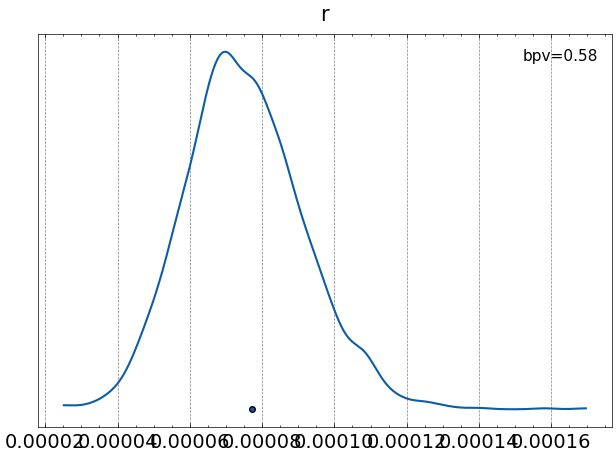

In [ ]:
az.plot_bpv(idatas[0], kind="t_stat", bpv=True, var_names=["r"], t_stat="mean")

In [ ]:
test_data = xarray.open_dataset(Path("data/test_heteroscedastic_data.nc"))
display(test_data)

<xarray.Dataset> Size: 112kB
Dimensions:    (sample: 1000, parameter: 5, species: 5)
Coordinates:
  * sample     (sample) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
  * parameter  (parameter) <U3 60B 'T' 'p' 'c2h' 'f' 'c2i'
  * species    (species) <U3 60B 'CO2' 'H2' 'H2O' 'CH4' 'I'
Data variables:
    samples    (sample, parameter) float64 40kB ...
    T          (sample) float64 8kB ...
    p          (sample, species) float64 40kB ...
    latent_r   (sample) float64 8kB ...
    obs_r      (sample) float64 8kB ...
Attributes:
    noise:    heteroscedastic
    sigma:    1e-05

In [ ]:
from HSA_Mo_B_009_pyro import validate_against_holdout

postdatas = []
for idata in idatas:
    postdata = validate_against_holdout(
        idata=idata,
        holdout=test_data,
        num_samples=985,
    )
    postdatas.append(postdata)

torch.Size([1000, 1]) torch.Size([1000, 5]) None


c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\data\inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



torch.Size([1000, 1]) torch.Size([1000, 5]) None


c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\data\inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



torch.Size([1000, 1]) torch.Size([1000, 5]) None


...

c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\data\inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



torch.Size([1000, 1]) torch.Size([1000, 5]) None


c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\data\inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



torch.Size([1000, 1]) torch.Size([1000, 5]) None


c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\data\inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



In [ ]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
)
def interactive(i):
    az.plot_ppc(
        postdatas[i],
        num_pp_samples=100,
        kind="kde",
        # var_names=["r_pred"],
    )
    ax = plt.gca()
    ax.set_xlim(None, 0.0006)

interactive(children=(IntSlider(value=0, description='Iteration:', max=15), Output()), _dom_classes=('widget-i…

In [ ]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
)
def interactive(i):
    az.plot_bpv(
        postdatas[i],
        kind="p_value",
        bpv=True,
        # var_names=["r_pred"],
    )

interactive(children=(IntSlider(value=0, description='Iteration:', max=15), Output()), _dom_classes=('widget-i…

In [ ]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
)
def interactive(i):
    az.plot_bpv(
        postdatas[i],
        kind="t_stat",
        bpv=True,
        # var_names=["r_pred"],
        t_stat="mean",
    )

interactive(children=(IntSlider(value=0, description='Iteration:', max=15), Output()), _dom_classes=('widget-i…

In [ ]:
proposals = test_data.samples.values
r_obs = test_data.obs_r.values
r_lat = test_data.latent_r.values


@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
    j=IntSlider(
        min=0, max=len(proposals) - 1, step=1, value=0, description="Proposal:"
    ),
)
def plot_interactive(i, j):
    fig = ICIW_Plots.figure(layout="double_column")
    ax = ICIW_Plots.make_rect_ax(
        fig,
        ax_width=7.5 * ICIW_Plots.cm2inch,
        ax_height=5.0 * ICIW_Plots.cm2inch,
        xlabel="$T$ / K",
        ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
    )
    test_res = evaluate_conditions(
        proposal=proposals[j],
        idata=idatas[i],
        key="posterior" if i > 0 else "prior",
    )
    true_res = evaluate_true_model(
        proposal=proposals[j],
    )
    plot_predictions(
        fig,
        ax,
        proposal=proposals[j],
        posterior_preds=test_res,
        true_preds=true_res,
        T_range=np.linspace(500, 600, 100),
    )
    fig = plt.gcf()
    axs = fig.axes
    axs[0].set(
        ylim=(0, 0.0006),
        xlabel="$T$ / K",
        xlim=(500, 600),
    )
    axs[0].scatter(
        proposals[j, 0], r_obs[j], color="red", label="Observed Data Point", zorder=5
    )
    axs[0].scatter(
        proposals[j, 0], r_lat[j], color="green", label="Latent Data Point", zorder=5
    )
    plt.show()

interactive(children=(IntSlider(value=0, description='Iteration:', max=15), IntSlider(value=0, description='Pr…

In [ ]:
def bRMSE(postdata, var_name):
    true = postdata.observed_data[var_name].values
    pred = postdata.posterior_predictive[var_name].values
    res = true - pred
    rmse_vals = np.sqrt(np.mean(res**2, axis=2)).squeeze()
    rmse_da = xarray.DataArray(
        data=rmse_vals,
        dims=["draw"],
    )
    return rmse_da


RMSEs = {"r": [], "r_pred": []}
for postdata in postdatas:
    RMSE = bRMSE(postdata, "r_pred")
    RMSEs["r_pred"].append(RMSE)
    RMSE = bRMSE(postdata, "r")
    RMSEs["r"].append(RMSE)

RMSEar = {
    "r": np.array([rmse.values for rmse in RMSEs["r"]]),
    "r_pred": np.array([rmse.values for rmse in RMSEs["r_pred"]]),
}

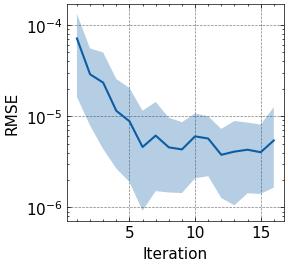

In [ ]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="Iteration",
    ylabel="RMSE",
    yscale="log",
)
ax.plot(np.arange(1, len(RMSEar["r"]) + 1), RMSEar["r"].mean(axis=1))
ax.fill_between(
    np.arange(1, len(RMSEar["r"]) + 1),
    np.quantile(RMSEar["r"], 0.025, axis=1),
    np.quantile(RMSEar["r"], 0.975, axis=1),
    alpha=0.3,
)

In [ ]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="Iteration",
    ylabel="RMSE",
    yscale="log",
)
ax.plot(np.arange(1, len(RMSEar["r_pred"]) + 1), RMSEar["r_pred"].mean(axis=1))
ax.fill_between(
    np.arange(1, len(RMSEar["r_pred"]) + 1),
    np.quantile(RMSEar["r_pred"], 0.025, axis=1),
    np.quantile(RMSEar["r_pred"], 0.975, axis=1),
    alpha=0.3,
)